# Exploratory Data Analysis: CMAPSS FD002

**CS5998 Capstone: Predicting Remaining Useful Life in Turbofan Engines**

FD002 has the same fault mode as FD001 (High-Pressure Compressor degradation), but its engines operate under **six different flight conditions**. The project uses it to test whether the models stay reliable when operating conditions vary.

The general sensor analysis is in `01_eda_fd001.ipynb`. This notebook only checks whether FD001's conclusions survive in FD002:

1. Can the six operating conditions be identified from the three operating settings?
2. How much do the conditions affect the sensors, and does normalising within each condition recover the degradation signal?
3. Which sensors carry no information once conditions are accounted for?
4. Do the degradation trends and the RUL cap still hold?
5. Are any test engines shorter than the 30-cycle window?

As in FD001, all statistics are fitted on **training engines only**; the test set is only used for sizes and lengths.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from src.config import load_config, resolve_path
from src.data.download import main as download_cmapss
from src.data.load import OP_SETTINGS, SENSORS, load_subset
from src.data.quality import find_cycle_gaps, missing_report
from src.features.labels import add_train_rul

config = load_config()
RUL_CAP = config["preprocessing"]["rul_cap"]
WINDOW = config["preprocessing"]["window_size"]
FD001_DROP = [f"sensor_{i}" for i in config["preprocessing"]["drop_sensors"]["FD001"]]

if not (resolve_path(config["data"]["raw_dir"]) / "train_FD002.txt").exists():
    download_cmapss([])

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.bottom": False, "ytick.left": False,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)

train, test, rul = load_subset("FD002")
labelled = add_train_rul(train, cap=None).rename(columns={"rul": "rul_linear"})
labelled["rul_capped"] = labelled["rul_linear"].clip(upper=RUL_CAP)

## 1. Data overview

In [2]:
def summarise(df):
    lengths = df.groupby("unit")["cycle"].max()
    return {
        "engines": df["unit"].nunique(), "rows": len(df),
        "shortest engine (cycles)": lengths.min(), "median engine (cycles)": lengths.median(),
        "longest engine (cycles)": lengths.max(),
        "channels with missing values": len(missing_report(df)), "skipped cycles": len(find_cycle_gaps(df)),
    }

pd.DataFrame({"train": summarise(train), "test": summarise(test)})

,train,test
engines,260.0,259.0
rows,53759.0,33991.0
shortest engine (cycles),128.0,21.0
median engine (cycles),199.0,132.0
longest engine (cycles),378.0,367.0
channels with missing values,0.0,0.0
skipped cycles,0.0,0.0


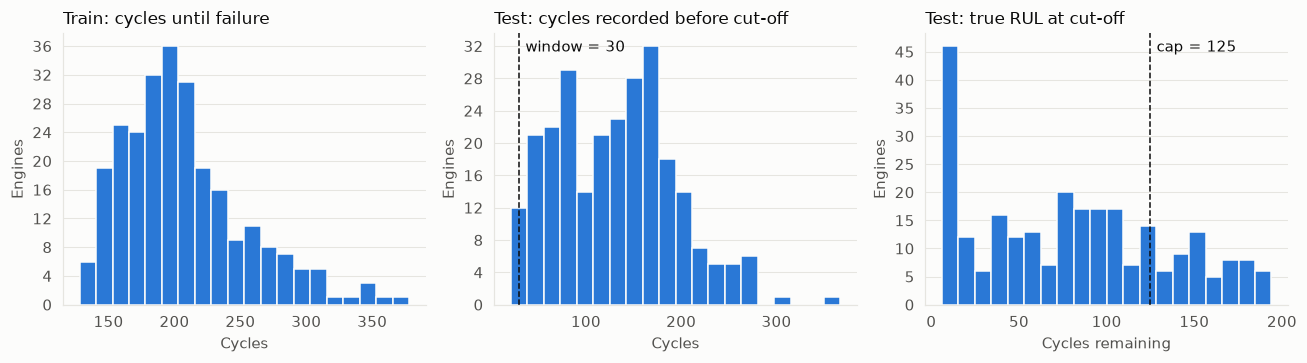

Test engines shorter than the 30-cycle window: 6 of 259
Test engines with true RUL above the cap: 57 of 259 (largest 194)
Test engines with true RUL of 15 or less: 46 of 259


In [3]:
train_life = train.groupby("unit")["cycle"].max()
test_seen = test.groupby("unit")["cycle"].max()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
panels = [
    (train_life, "Train: cycles until failure", "Cycles"),
    (test_seen, "Test: cycles recorded before cut-off", "Cycles"),
    (rul["rul"], "Test: true RUL at cut-off", "Cycles remaining"),
]
for ax, (values, title, xlabel) in zip(axes, panels):
    ax.hist(values, bins=20, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
    ax.set(title=title, xlabel=xlabel, ylabel="Engines")
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].axvline(WINDOW, color=INK, linewidth=1, linestyle="--")
axes[1].annotate(f"window = {WINDOW}", (WINDOW, axes[1].get_ylim()[1]), xytext=(4, -12),
                 textcoords="offset points", ha="left", color=INK)
axes[2].axvline(RUL_CAP, color=INK, linewidth=1, linestyle="--")
axes[2].annotate(f"cap = {RUL_CAP}", (RUL_CAP, axes[2].get_ylim()[1]), xytext=(4, -12),
                 textcoords="offset points", ha="left", color=INK)
fig.tight_layout()
plt.show()

print(f"Test engines shorter than the {WINDOW}-cycle window: {(test_seen < WINDOW).sum()} of {len(test_seen)}")
print(f"Test engines with true RUL above the cap: {(rul['rul'] > RUL_CAP).sum()} of {len(rul)} (largest {rul['rul'].max()})")
print(f"Test engines with true RUL of 15 or less: {(rul['rul'] <= 15).sum()} of {len(rul)}")

**Findings**

- **The data is complete:** no missing values and no skipped cycles, as in FD001.
- **Training lifetimes match FD001:** 128 to 378 cycles (median 199, against 199 in FD001), with 2.6 times as many engines.
- **6 of 259 test engines are shorter than the 30-cycle window,** the shortest at 21 cycles. Unlike FD001, the windowing code needs a fallback for short engines.
- **The test RUL distribution is much wider than FD001's.** 57 of 259 test engines (22%) have a true RUL above the cap, up to 194, so a model capped at 125 underestimates those engines by up to 69 cycles. At the other end, 46 engines are within 15 cycles of failure. **The choice between capped and uncapped evaluation matters far more here than in FD001.**

## 2. Identifying the operating conditions

Each row has three operating settings: altitude, Mach number and throttle resolver angle (TRA). Plotting the training rows shows how many distinct conditions there are.

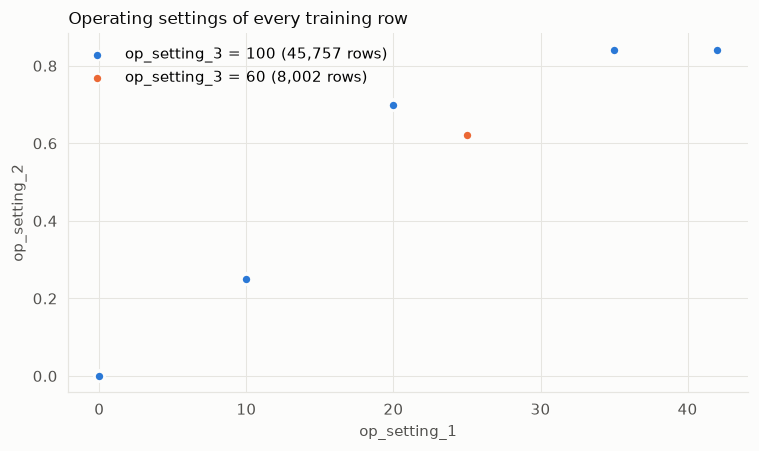

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for tra, colour in [(100, BLUE), (60, ORANGE)]:
    rows = train[train["op_setting_3"].round() == tra]
    ax.scatter(rows["op_setting_1"], rows["op_setting_2"], s=40, color=colour, edgecolor="#fcfcfb",
               linewidth=1.5, label=f"op_setting_3 = {tra} ({len(rows):,} rows)")
ax.set(title="Operating settings of every training row", xlabel="op_setting_1", ylabel="op_setting_2")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

The rows collapse onto six points, so k-means with six clusters is enough to label each row with its condition. It is fitted on training rows, and conditions are numbered 1 to 6 in order of `op_setting_1` for readability.

In [5]:
kmeans = KMeans(n_clusters=6, n_init=10, random_state=config["seed"]).fit(train[OP_SETTINGS])
order = np.argsort(kmeans.cluster_centers_[:, 0])
relabel = {cluster: number for number, cluster in enumerate(order, start=1)}

def assign_condition(df):
    return pd.Series(kmeans.predict(df[OP_SETTINGS]), index=df.index).map(relabel)

labelled["condition"] = assign_condition(labelled)
test_condition = assign_condition(test)

centres = pd.DataFrame(kmeans.cluster_centers_[order], columns=OP_SETTINGS, index=pd.Index(range(1, 7), name="condition"))
centres["% of train rows"] = labelled["condition"].value_counts(normalize=True).sort_index() * 100
centres["% of test rows"] = test_condition.value_counts(normalize=True).sort_index() * 100
display(centres.round(3))

def max_distance(df):
    return kmeans.transform(df[OP_SETTINGS]).min(axis=1).max()

gaps = [np.linalg.norm(a - b) for i, a in enumerate(kmeans.cluster_centers_) for b in kmeans.cluster_centers_[i + 1:]]
print(f"Furthest row from its condition centre: train {max_distance(train):.4f}, test {max_distance(test):.4f}")
print(f"Closest pair of condition centres: {min(gaps):.2f} apart")
agrees = pd.crosstab(labelled["condition"], labelled["op_setting_1"].round()).gt(0).sum(axis=1).eq(1).all()
print(f"Rounding op_setting_1 to a whole number gives the same six groups: {agrees}")

,op_setting_1,op_setting_2,op_setting_3,% of train rows,% of test rows
condition,,,,,
1,0.002,0.000,100.0,14.963,15.145
2,10.003,0.250,100.0,15.060,15.025
3,20.003,0.701,100.0,15.108,14.895
4,25.003,0.621,60.0,14.885,14.833
5,35.003,0.841,100.0,14.950,15.145
6,42.003,0.840,100.0,25.034,24.957


Furthest row from its condition centre: train 0.0053, test 0.0053
Closest pair of condition centres: 7.00 apart
Rounding op_setting_1 to a whole number gives the same six groups: True


### How often do engines change condition?

Cycles where the condition differs from the previous cycle: 82.5%


,mean % of an engine's cycles,std across engines (pct points),correlation with engine lifetime
condition,,,
1,14.98,2.04,-0.04
2,15.05,2.09,0.02
3,15.11,2.07,0.00
4,14.89,2.14,-0.00
5,14.98,1.97,-0.06
6,25.00,2.34,0.07


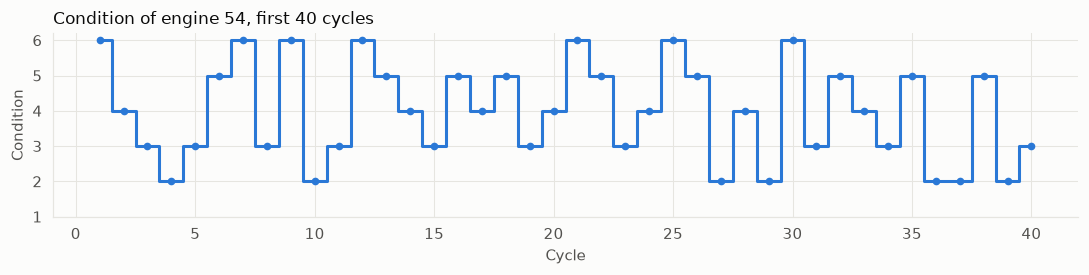

In [6]:
switches = labelled.groupby("unit")["condition"].diff().ne(0) & labelled["cycle"].gt(1)
print(f"Cycles where the condition differs from the previous cycle: {switches[labelled['cycle'] > 1].mean():.1%}")

mix = pd.crosstab(labelled["unit"], labelled["condition"], normalize="index") * 100
summary = pd.DataFrame({
    "mean % of an engine's cycles": mix.mean(),
    "std across engines (pct points)": mix.std(),
    "correlation with engine lifetime": mix.corrwith(train_life),
})
display(summary.round(2))

unit = train_life.sort_values().index[len(train_life) // 2]
first = labelled[labelled["unit"] == unit].head(40)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.step(first["cycle"], first["condition"], where="mid", color=BLUE)
ax.plot(first["cycle"], first["condition"], "o", color=BLUE, markersize=4)
ax.set(title=f"Condition of engine {unit}, first 40 cycles", xlabel="Cycle", ylabel="Condition", yticks=range(1, 7))
fig.tight_layout()
plt.show()

**Findings**

- **There are exactly six operating conditions,** and they are trivial to identify. Every row lies within 0.0053 of a condition centre, while the closest two centres are 7.00 apart. Test rows fall on the same six points, so a model fitted on training data labels them reliably.
- **`op_setting_1` alone identifies the condition** when rounded to a whole number. That simple rule is useful for the API, which then needs no fitted clustering model.
- **Engines switch condition almost every cycle:** 82.5% of cycles differ from the previous one. Consecutive readings therefore come from different conditions, so **normalisation must happen before rolling-window statistics or sequences are built.** Otherwise a 30-cycle window mixes six different sensor levels.
- **Conditions are not linked to lifetime.** Each engine spends about 15% of its cycles in each condition (25% in condition 6), varying by only about 2 percentage points between engines, and no condition's share correlates with lifetime beyond 0.07 in magnitude. Operating conditions are therefore something to remove from the signal, not a cause of failure to model.

## 3. How much do conditions affect the sensors?

The share of each sensor's variance explained by the operating condition alone, and each sensor's correlation with capped RUL before and after normalising. Normalising means subtracting the mean and dividing by the standard deviation **within each condition**, using training statistics. A sensor that never varies within a condition is set to 0.

In [7]:
by_condition = labelled.groupby("condition")[SENSORS]
cond_mean, cond_std = by_condition.transform("mean"), by_condition.transform("std")
normalised = ((labelled[SENSORS] - cond_mean) / cond_std.replace(0, np.nan)).fillna(0)

varying = [s for s in SENSORS if normalised[s].std() > 0]  # skip sensors constant within every condition
effect = pd.DataFrame({
    "% variance explained by condition": 100 * (1 - (labelled[varying] - cond_mean[varying]).var() / labelled[varying].var()),
    "correlation with RUL: raw": labelled[varying].corrwith(labelled["rul_capped"]),
    "correlation with RUL: normalised": normalised[varying].corrwith(labelled["rul_capped"]),
})
effect.sort_values("correlation with RUL: normalised", key=np.abs, ascending=False).round(3)

,% variance explained by condition,correlation with RUL: raw,correlation with RUL: normalised
sensor_11,99.452,-0.055,-0.771
sensor_4,99.566,-0.048,-0.738
sensor_15,99.733,-0.040,-0.724
sensor_17,99.734,-0.033,-0.649
sensor_2,99.986,-0.007,-0.630
sensor_3,99.712,-0.032,-0.618
sensor_12,99.999,0.002,0.535
sensor_7,99.998,0.002,0.510
sensor_20,99.982,0.007,0.484
sensor_21,99.983,0.006,0.479


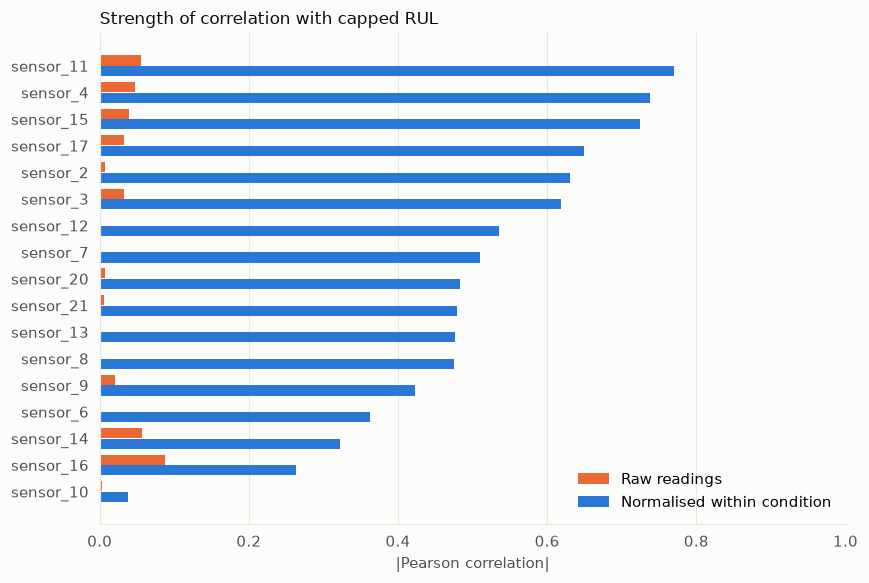

In [8]:
ranked = effect.sort_values("correlation with RUL: normalised", key=np.abs)
y = np.arange(len(ranked))
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh(y + 0.2, ranked["correlation with RUL: raw"].abs(), height=0.38, color=ORANGE, label="Raw readings")
ax.barh(y - 0.2, ranked["correlation with RUL: normalised"].abs(), height=0.38, color=BLUE, label="Normalised within condition")
ax.set_yticks(y, ranked.index)
ax.set(title="Strength of correlation with capped RUL", xlabel="|Pearson correlation|", xlim=(0, 1))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

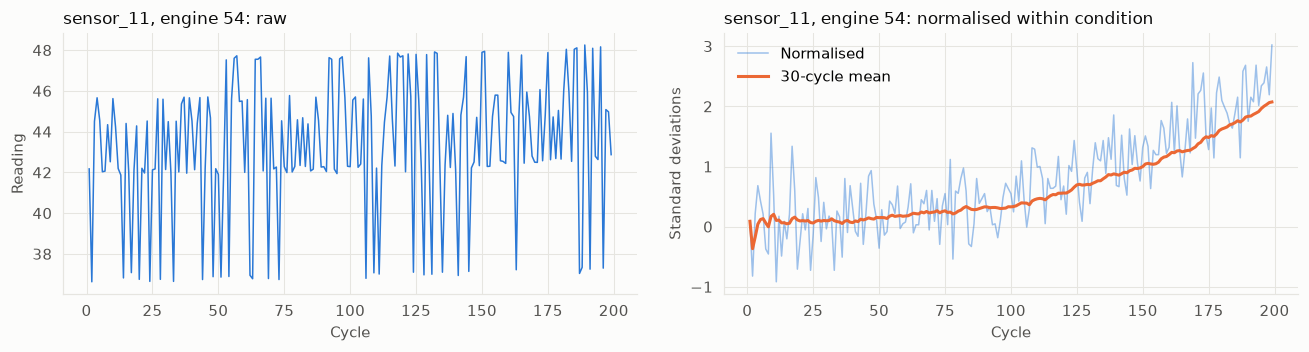

In [9]:
engine = labelled[labelled["unit"] == unit]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].plot(engine["cycle"], engine["sensor_11"], color=BLUE, linewidth=1)
axes[0].set(title=f"sensor_11, engine {unit}: raw", xlabel="Cycle", ylabel="Reading")
axes[1].plot(engine["cycle"], normalised.loc[engine.index, "sensor_11"], color=BLUE, linewidth=1, alpha=0.45, label="Normalised")
axes[1].plot(engine["cycle"], normalised.loc[engine.index, "sensor_11"].rolling(WINDOW, min_periods=1).mean(),
             color=ORANGE, label=f"{WINDOW}-cycle mean")
axes[1].set(title=f"sensor_11, engine {unit}: normalised within condition", xlabel="Cycle", ylabel="Standard deviations")
axes[1].legend(loc="upper left")
fig.tight_layout()
plt.show()

**Findings**

- **Operating conditions dominate the raw sensors.** Condition alone explains over 96% of the variance in every sensor that changes within a condition, except sensor 16 (88.5%).
- **Raw readings are almost useless for predicting RUL:** no sensor's raw correlation with capped RUL exceeds 0.09 in magnitude. A model given raw FD002 readings would mostly learn which condition each row is in.
- **Normalising within each condition recovers the signal.** Sensor 11's correlation goes from -0.06 to -0.77, sensor 4's from -0.05 to -0.74, and sensor 15's from -0.04 to -0.72. These are close to their FD001 values (-0.78, -0.76 and -0.72).
- **The single-engine chart shows the effect directly:** raw sensor 11 jumps between condition levels with no visible trend, while the normalised series shows a clear rise towards failure.

**Decision:** per-condition normalisation, fitted on training engines only, is a required FD002 pipeline step, applied before any windowing.

## 4. Which sensors carry no information?

In FD001, seven sensors were dropped. Here they are checked **within each condition**, because a sensor that only changes when the condition changes tells us nothing about wear.

In [10]:
within = labelled.groupby("condition")[SENSORS].nunique()
check = pd.DataFrame({
    "conditions where constant": within.eq(1).sum(),
    "most distinct values in a condition": within.max(),
    "correlation with RUL: normalised": normalised.corrwith(labelled["rul_capped"]),
    "dropped in FD001": [s in FD001_DROP for s in SENSORS],
})
check[check["most distinct values in a condition"].le(3) | check["dropped in FD001"]]

,conditions where constant,most distinct values in a condition,correlation with RUL: normalised,dropped in FD001
sensor_1,6,1,NaN,True
sensor_5,6,1,NaN,True
sensor_6,0,3,-0.363,True
sensor_10,1,2,0.038,True
sensor_16,5,2,-0.263,True
sensor_18,6,1,NaN,True
sensor_19,6,1,NaN,True


In [11]:
for sensor in ["sensor_6", "sensor_10", "sensor_16"]:
    counts = labelled.groupby("condition")[sensor].value_counts().rename("rows").reset_index()
    print(sensor, "| values per condition:", counts.groupby("condition")[sensor].apply(list).to_dict())

sensor_6 | values per condition: {1: [21.61, 21.6], 2: [15.49, 15.5], 3: [13.66, 13.65, 13.67], 4: [9.03, 9.02, 9.04], 5: [8.0, 8.01], 6: [5.72, 5.71]}
sensor_10 | values per condition: {1: [1.3], 2: [1.26, 1.25], 3: [1.08, 1.07], 4: [0.94, 0.93], 5: [1.02, 1.03], 6: [1.02, 1.03]}
sensor_16 | values per condition: {1: [0.03], 2: [0.03], 3: [0.02, 0.03], 4: [0.02], 5: [0.02], 6: [0.02]}


**Findings**

- **Sensors 1, 5, 18 and 19 are constant within every condition.** They only change when the condition changes, so they carry no wear information. Drop them.
- **Sensor 10 is near-constant:** at most two values per condition, constant in condition 1, and a normalised correlation of only 0.04. Drop it.
- **Sensor 16 varies in only one condition** (condition 3), where it takes two values. Its normalised correlation of -0.26 comes entirely from that condition, so it is not a usable general signal. Drop it.
- **Sensor 6 differs from FD001.** It takes two or three values per condition, one measurement step apart, but after normalisation it correlates -0.36 with capped RUL. That is stronger than sensor 14 (-0.32), which is kept. Dropping it is not clearly justified for FD002.

**Decision:** the FD001 drop list (1, 5, 6, 10, 16, 18, 19) can be reused for FD002, so both datasets share one feature set. Keeping sensor 6 for FD002 should then be tested against validation error, not assumed either way.

## 5. Degradation trends after normalisation

The same view as FD001: sensors aligned on cycles before failure, with the median across engines and a band covering the middle 80%. Readings are normalised within condition, so the y-axis is in standard deviations.

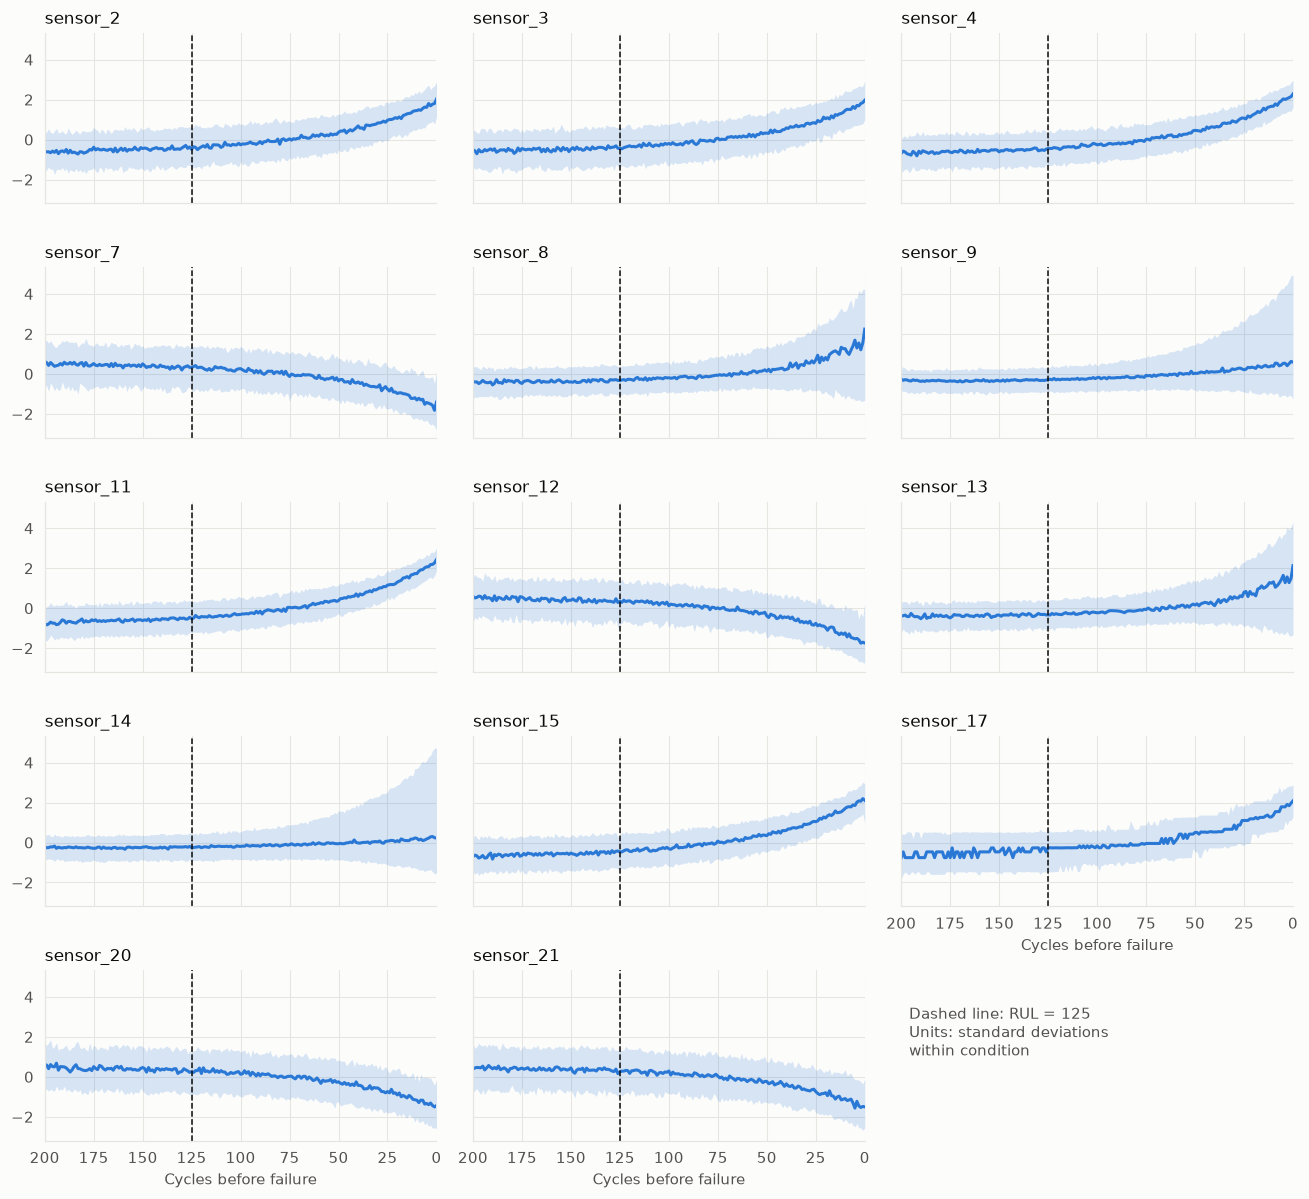

In [12]:
KEPT = [s for s in SENSORS if s not in FD001_DROP]
window = normalised.join(labelled["rul_linear"])
window = window[window["rul_linear"] <= 200]
by_rul = window.groupby("rul_linear")[KEPT]
median, low, high = by_rul.median(), by_rul.quantile(0.1), by_rul.quantile(0.9)

fig, axes = plt.subplots(5, 3, figsize=(12, 11), sharex=True, sharey=True)
for ax, sensor in zip(axes.flat, KEPT):
    ax.fill_between(median.index, low[sensor], high[sensor], color=BLUE, alpha=0.18, linewidth=0)
    ax.plot(median.index, median[sensor], color=BLUE)
    ax.axvline(RUL_CAP, color=INK, linewidth=1, linestyle="--")
    ax.set_title(sensor)
    ax.set_xlim(200, 0)
axes.flat[-1].axis("off")
axes.flat[-1].text(0.02, 0.5, f"Dashed line: RUL = {RUL_CAP}\nUnits: standard deviations\nwithin condition", color=MUTED,
                   transform=axes.flat[-1].transAxes)
for ax in (axes[3, 2], *axes[4, :2]):
    ax.set_xlabel("Cycles before failure")
    ax.tick_params(labelbottom=True)
fig.tight_layout()
plt.show()

### Is the RUL cap still supported?

The same average-drift check as FD001: the 14 kept sensors, normalised, flipped so that all rise towards failure, and averaged.

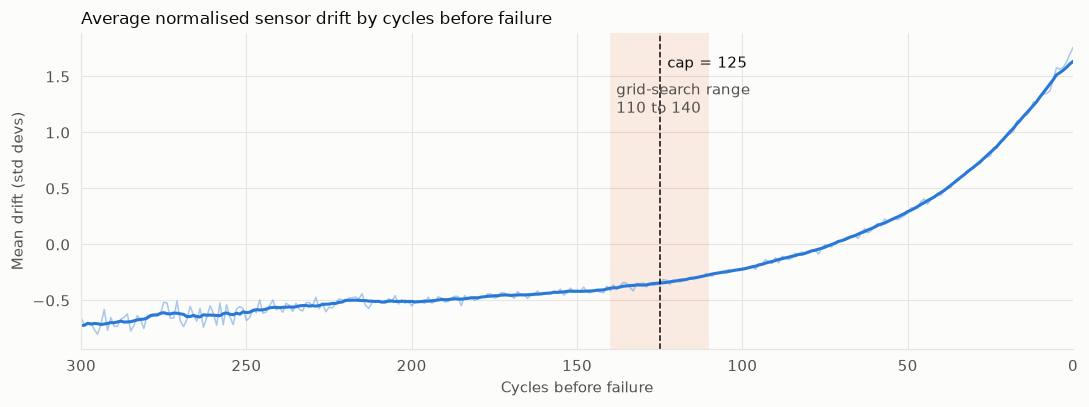

Drift first exceeds baseline + 3 x noise at RUL = 118
Share of total drift already reached at the cap: 10.6%
Engines contributing to the baseline (lifetime above 200 cycles): 124 of 260
PCA on normalised sensors: PC1 explains 47.0% of variance, correlation with capped RUL 0.835 in magnitude


In [13]:
signs = -np.sign(normalised[KEPT].corrwith(labelled["rul_linear"]))
drift = (normalised[KEPT] * signs).mean(axis=1).groupby(labelled["rul_linear"]).median()
drift = drift[drift.index <= 300].sort_index()
baseline, spread = drift[drift.index >= 200].median(), drift[drift.index >= 200].std()
smooth = drift.rolling(11, center=True, min_periods=1).mean()
departure = smooth[smooth > baseline + 3 * spread].index.max()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(drift.index, drift, color=BLUE, linewidth=1, alpha=0.4)
ax.plot(smooth.index, smooth, color=BLUE)
ax.axvspan(110, 140, color=ORANGE, alpha=0.12, linewidth=0)
ax.axvline(RUL_CAP, color=INK, linewidth=1, linestyle="--")
ax.annotate(f"cap = {RUL_CAP}", (RUL_CAP, smooth.max()), xytext=(5, -4), textcoords="offset points", color=INK)
ax.annotate("grid-search range\n110 to 140", (140, smooth.max() * 0.72), xytext=(4, 0), textcoords="offset points", color=MUTED)
ax.set(title="Average normalised sensor drift by cycles before failure", xlabel="Cycles before failure",
       ylabel="Mean drift (std devs)", xlim=(300, 0))
fig.tight_layout()
plt.show()

print(f"Drift first exceeds baseline + 3 x noise at RUL = {departure}")
print(f"Share of total drift already reached at the cap: {(smooth.loc[RUL_CAP] - baseline) / (smooth.loc[0] - baseline):.1%}")
print(f"Engines contributing to the baseline (lifetime above 200 cycles): {(train_life > 200).sum()} of {len(train_life)}")

pca = PCA().fit(normalised[KEPT])
pc1 = pd.Series(pca.transform(normalised[KEPT])[:, 0], index=labelled.index)
print(f"PCA on normalised sensors: PC1 explains {pca.explained_variance_ratio_[0]:.1%} of variance, "
      f"correlation with capped RUL {abs(pc1.corr(labelled['rul_capped'])):.3f} in magnitude")

**Findings**

- **Once normalised, the FD002 trends match FD001.** Sensors 2, 3, 4, 11, 15 and 17 rise, while 7, 12, 20 and 21 fall. Sensors 9 and 14 again barely move at the median while the band fans out near failure, the same inconsistent behaviour seen in FD001.
- **Sensors 8 and 13 spread out sharply between engines in the last 25 cycles,** with the band reaching about 4 standard deviations, so their late readings vary a lot from engine to engine.
- **The RUL cap is still supported.** Drift first departs from baseline at RUL 118, inside the 110 to 140 range, though later than FD001's 139. Only 10.6% of the total drift has happened by RUL 125, close to FD001's 11.3%.
- **The baseline is more reliable than FD001's:** 124 of 260 engines live past 200 cycles, against 46 of 100.
- **A health index still works:** on normalised sensors, PC1 explains 47.0% of variance (64.3% in FD001) and correlates 0.835 in magnitude with capped RUL, as strongly as in FD001.

## 6. Test engines shorter than the window

In [14]:
short = test_seen[test_seen < WINDOW].rename("cycles recorded").to_frame()
short["true RUL"] = rul.set_index("unit").loc[short.index, "rul"]
short["cycles missing from window"] = WINDOW - short["cycles recorded"]
short.sort_values("cycles recorded")

,cycles recorded,true RUL,cycles missing from window
unit,,,
83,21,146,9
59,22,178,8
28,23,138,7
201,25,111,5
122,29,145,1
223,29,151,1


**Findings**

- **The six short engines are early in life:** five have a true RUL above the cap (138 to 178), and all six are at least 111 cycles from failure.
- **They need a fallback,** because a model cannot be given a 30-cycle window that doesn't exist. The usual options are padding the start of the window (repeating the first reading, or zeros after normalisation) or using a shorter window. Padding with the first reading is the simplest fit for both the tree models and the CNN-BiLSTM.
- **The risk is low.** These engines are far from failure, so the target is likely to be at the cap anyway. They are still part of the test set, so the decision must be documented.

## 7. Summary: what changes for FD002

| Question | FD001 | FD002 | Pipeline decision for FD002 |
|---|---|---|---|
| Operating conditions | 1 | 6, switching on 82.5% of cycles | Label each row's condition from training-fitted k-means (or rounded `op_setting_1`) |
| Raw sensor signal | Correlations up to 0.78 | Below 0.09; condition explains over 96% of variance | **Normalise within condition before windowing**, using training statistics only |
| Normalised signal | Not needed | Correlations up to 0.77, matching FD001 | Same 14 sensors as FD001 |
| Drop list | 1, 5, 6, 10, 16, 18, 19 | Same list, but sensor 6 now correlates -0.36 | Reuse FD001 list, then test keeping sensor 6 |
| RUL cap | Departs at 139, 11.3% of drift by 125 | Departs at 118, 10.6% of drift by 125 | Keep 125, then grid search 110 to 140 |
| Test engines shorter than window | 0 | 6 (shortest 21 cycles) | Pad the window start with the first reading |
| Test RUL above cap | 11 of 100 | 57 of 259, up to 194 | Report capped and uncapped RMSE and NASA score |

### Open items

1. **Config:** add an FD002 drop list (the same seven sensors) and a setting for per-condition normalisation, so the pipeline reads them instead of hard-coding them.
2. **Pipeline module:** move the condition labelling and normalisation out of this notebook into `src/features/`, with tests that check statistics are fitted on training data only. This is needed in Week 6 before any FD002 modelling.
3. **Evaluation:** decide the primary metric target (capped or uncapped test RUL) before training, and use it consistently for FD001 and FD002.